# EEG feature analysis, PCA, and classification

*Module 2 · Computational Neuroscience Independent Study*

I compare Rest and Task using a table of EEG features for 32 channels. I standardize the features, explore them with PCA, and fit a logistic regression classifier. The classifier score comes from a single split of channel-condition rows after scaling the full dataset. See the README for how that affects interpretation.

[Module overview](README.md) · [Execution notes](VERIFICATION.md)

In [2]:
import pandas as pd
import numpy as np

df = pd.read_excel('data/eeg_32ch_dataset.xlsx')

# 6.1 - Task 1: Check for missing variables
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

# Task 2: Identify channels with unusually high voltages
media_voltaje = df['MeanVoltage_uV'].mean()
std_voltaje = df['MeanVoltage_uV'].std()
umbral_alto = media_voltaje + 2*std_voltaje  # 2 desviaciones estandar

canales_altos = df[df['MeanVoltage_uV'] > umbral_alto]
print(f"\nChannels with unusually high voltage (> mean + 2*std = {umbral_alto:.2f}):")
print(canales_altos[['Channel', 'Region', 'MeanVoltage_uV', 'Condition']])

# 6.1 - Task 3: Standardize the power variables
columnas_a_estandarizar = ['DeltaPower', 'ThetaPower', 'AlphaPower', 'BetaPower', 'GammaPower', 'Entropy']

for col in columnas_a_estandarizar:
    df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()

print("\nStandardized columns added (mean ~0, std ~1):")
print(df[[c + '_z' for c in columnas_a_estandarizar]].agg(['mean', 'std']))

Missing values per column:
Channel           0
Region            0
MeanVoltage_uV    0
DeltaPower        0
ThetaPower        0
AlphaPower        0
BetaPower         0
GammaPower        0
Entropy           0
Condition         0
dtype: int64

Total missing values: 0

Channels with unusually high voltage (> mean + 2*std = 5.64):
   Channel   Region  MeanVoltage_uV Condition
34      F3  Frontal            5.94      Task

Standardized columns added (mean ~0, std ~1):
      DeltaPower_z  ThetaPower_z  AlphaPower_z   BetaPower_z  GammaPower_z  \
mean -5.516421e-16 -3.851086e-16  7.216450e-16  2.602085e-16  2.532696e-16   
std   1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00   

         Entropy_z  
mean -5.065393e-16  
std   1.000000e+00  


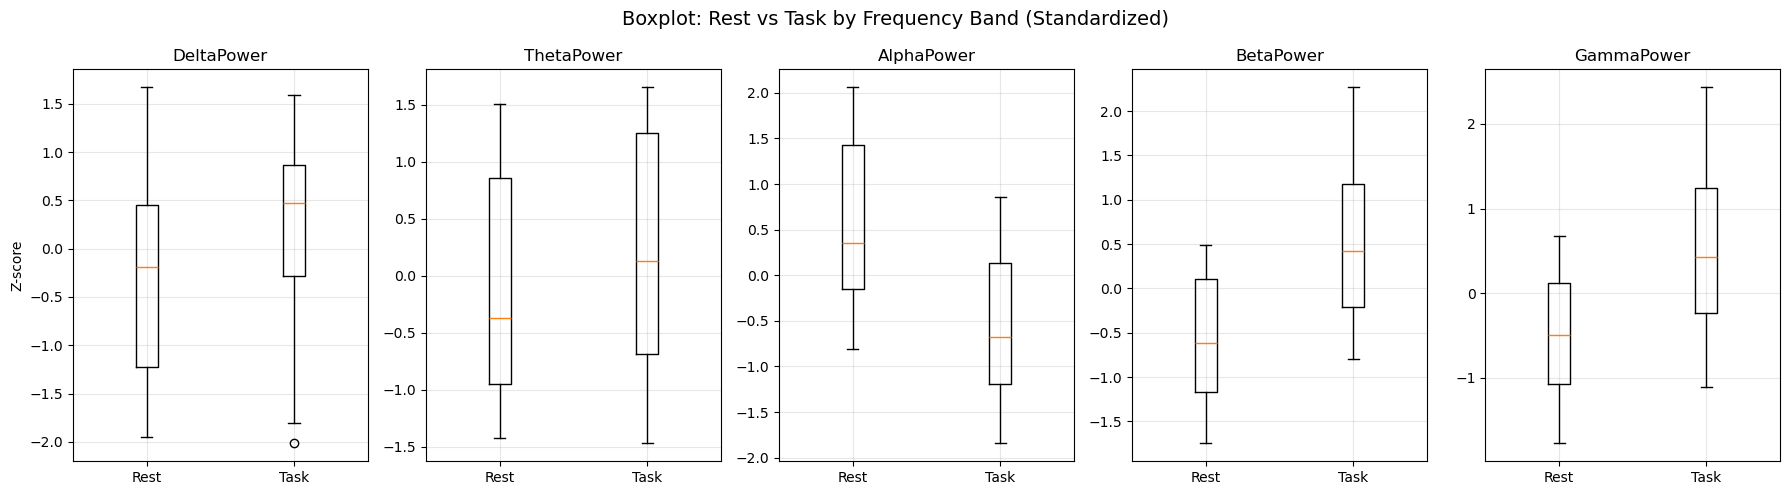

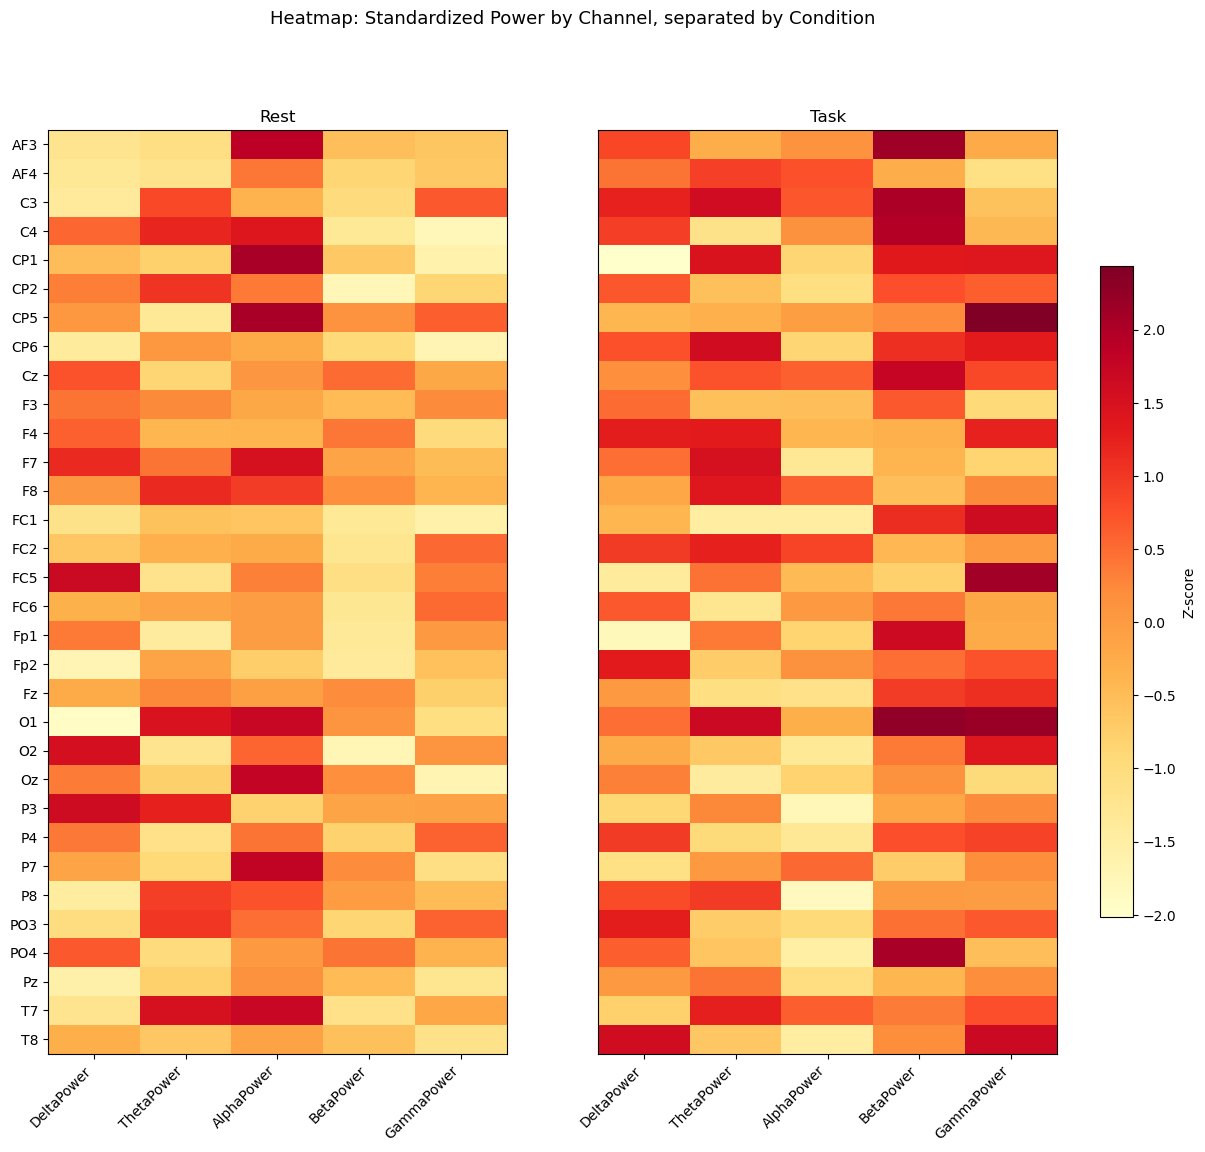

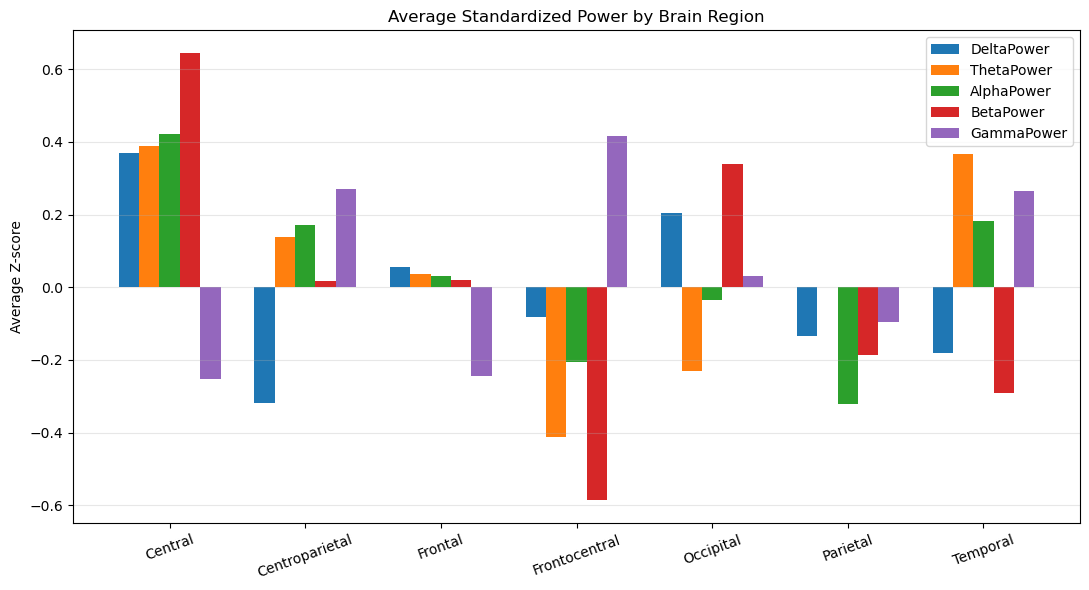

In [3]:
import matplotlib.pyplot as plt

# 6.2: Exploratory Statistics (standardized)

power_vars_z = ['DeltaPower_z', 'ThetaPower_z', 'AlphaPower_z', 'BetaPower_z', 'GammaPower_z']

# 1. Boxplot: Rest vs Task for each frequency band (standardized)
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharey=False)
for i, banda in enumerate(power_vars_z):
    data_rest = df[df['Condition']=='Rest'][banda]
    data_task = df[df['Condition']=='Task'][banda]
    axes[i].boxplot([data_rest, data_task], tick_labels=['Rest', 'Task'])
    axes[i].set_title(banda.replace('_z', ''))
    axes[i].grid(alpha=0.3)
axes[0].set_ylabel("Z-score")
plt.suptitle("Boxplot: Rest vs Task by Frequency Band (Standardized)", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Heatmap: average standardized power by channel
heatmap_rest = df[df['Condition']=='Rest'].groupby('Channel')[power_vars_z].mean()
heatmap_task = df[df['Condition']=='Task'].groupby('Channel')[power_vars_z].mean()
heatmap_task = heatmap_task.loc[heatmap_rest.index]

vmin = min(heatmap_rest.values.min(), heatmap_task.values.min())
vmax = max(heatmap_rest.values.max(), heatmap_task.values.max())

fig, axes = plt.subplots(1, 2, figsize=(14, 12))

im0 = axes[0].imshow(heatmap_rest.values, aspect='auto', cmap='YlOrRd', vmin=vmin, vmax=vmax)
axes[0].set_xticks(range(len(power_vars_z)))
axes[0].set_xticklabels([b.replace('_z', '') for b in power_vars_z], rotation=45, ha='right')
axes[0].set_yticks(range(len(heatmap_rest.index)))
axes[0].set_yticklabels(heatmap_rest.index)
axes[0].set_title("Rest")

im1 = axes[1].imshow(heatmap_task.values, aspect='auto', cmap='YlOrRd', vmin=vmin, vmax=vmax)
axes[1].set_xticks(range(len(power_vars_z)))
axes[1].set_xticklabels([b.replace('_z', '') for b in power_vars_z], rotation=45, ha='right')
axes[1].set_yticks([])
axes[1].set_title("Task")

fig.colorbar(im1, ax=axes, label='Z-score', fraction=0.03, pad=0.04)
plt.suptitle("Heatmap: Standardized Power by Channel, separated by Condition", fontsize=13)
plt.show()

# 3. Barplot: average standardized power by brain region
region_means = df.groupby('Region')[power_vars_z].mean()

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(region_means.index))
width = 0.15
for i, banda in enumerate(power_vars_z):
    ax.bar(x + i*width, region_means[banda], width, label=banda.replace('_z', ''))
ax.set_xticks(x + width*2)
ax.set_xticklabels(region_means.index, rotation=20)
ax.set_ylabel("Average Z-score")
ax.set_title("Average Standardized Power by Brain Region")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

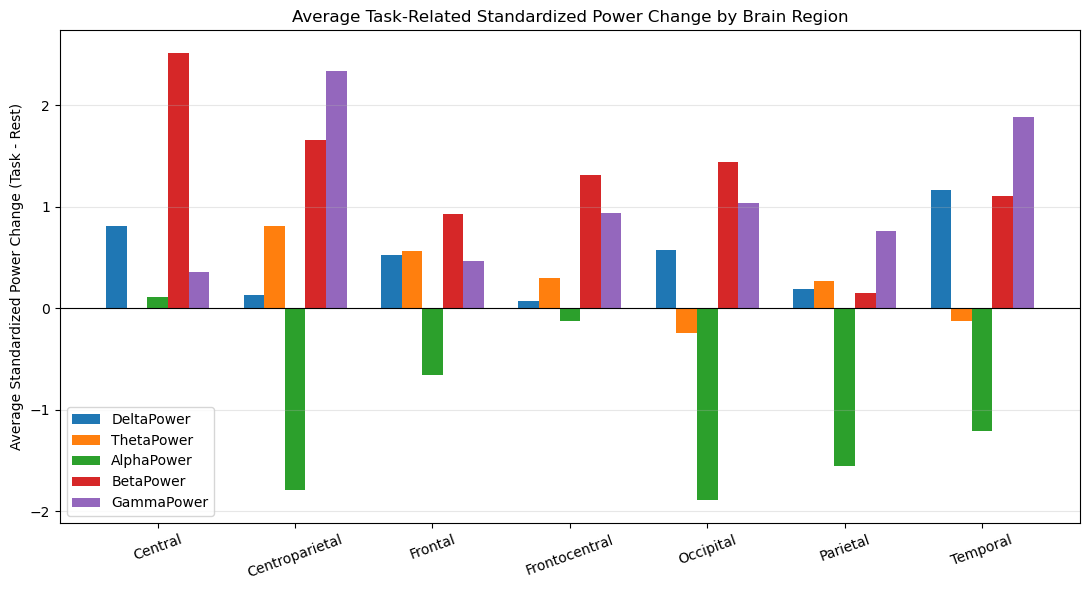

In [4]:
# Barplot: average task-related standardized power change by region

rest_data = df[df['Condition']=='Rest'].set_index('Channel')[power_vars_z + ['Region']]
task_data = df[df['Condition']=='Task'].set_index('Channel')[power_vars_z]
task_data = task_data.loc[rest_data.index]

cambio_por_canal = task_data[power_vars_z] - rest_data[power_vars_z]
cambio_por_canal['Region'] = rest_data['Region']

cambio_promedio_por_region = cambio_por_canal.groupby('Region')[power_vars_z].mean()

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(cambio_promedio_por_region.index))
width = 0.15
for i, banda in enumerate(power_vars_z):
    ax.bar(x + i*width, cambio_promedio_por_region[banda], width, label=banda.replace('_z', ''))

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x + width*2)
ax.set_xticklabels(cambio_promedio_por_region.index, rotation=20)
ax.set_ylabel("Average Standardized Power Change (Task - Rest)")
ax.set_title("Average Task-Related Standardized Power Change by Brain Region")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

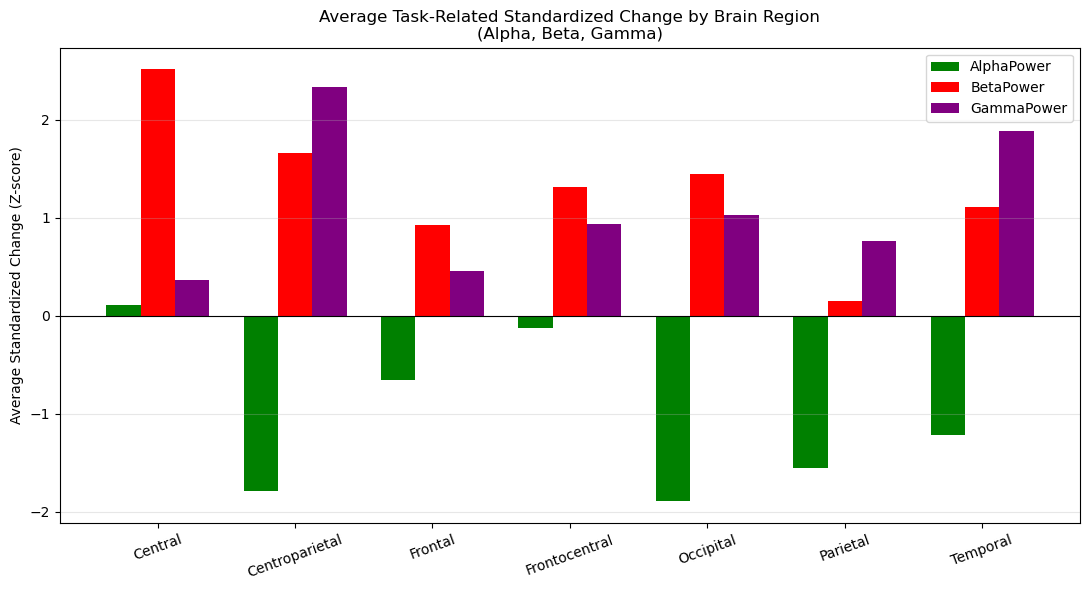

In [5]:
# Barplot: average task-related STANDARDIZED change by region (Alpha, Beta, Gamma)

relevant_bands_z = ['AlphaPower_z', 'BetaPower_z', 'GammaPower_z']

rest_data = df[df['Condition']=='Rest'].set_index('Channel')[relevant_bands_z + ['Region']]
task_data = df[df['Condition']=='Task'].set_index('Channel')[relevant_bands_z]
task_data = task_data.loc[rest_data.index]

change_z_per_channel = task_data[relevant_bands_z] - rest_data[relevant_bands_z]
change_z_per_channel['Region'] = rest_data['Region']
change_z_by_region = change_z_per_channel.groupby('Region')[relevant_bands_z].mean()

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(change_z_by_region.index))
width = 0.25
colors = ['green', 'red', 'purple']
for i, band in enumerate(relevant_bands_z):
    ax.bar(x + i*width, change_z_by_region[band], width, label=band.replace('_z', ''), color=colors[i])

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(x + width)
ax.set_xticklabels(change_z_by_region.index, rotation=20)
ax.set_ylabel("Average Standardized Change (Z-score)")
ax.set_title("Average Task-Related Standardized Change by Brain Region\n(Alpha, Beta, Gamma)")
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [6]:
# Sum of absolute standardized change by region, to identify the strongest task-related region
sum_abs_z_change = change_z_by_region.abs().sum(axis=1).sort_values(ascending=False)
print("Sum of |standardized change| by region (sorted):")
print(sum_abs_z_change.round(2))

print(f"\nStrongest region: {sum_abs_z_change.index[0]} (sum = {sum_abs_z_change.iloc[0]:.2f})")

Sum of |standardized change| by region (sorted):
Region
Centroparietal    5.78
Occipital         4.37
Temporal          4.21
Central           2.99
Parietal          2.46
Frontocentral     2.38
Frontal           2.05
dtype: float64

Strongest region: Centroparietal (sum = 5.78)


Variance explained by PC1: 36.2%
Variance explained by PC2: 19.6%
Total variance explained: 55.9%


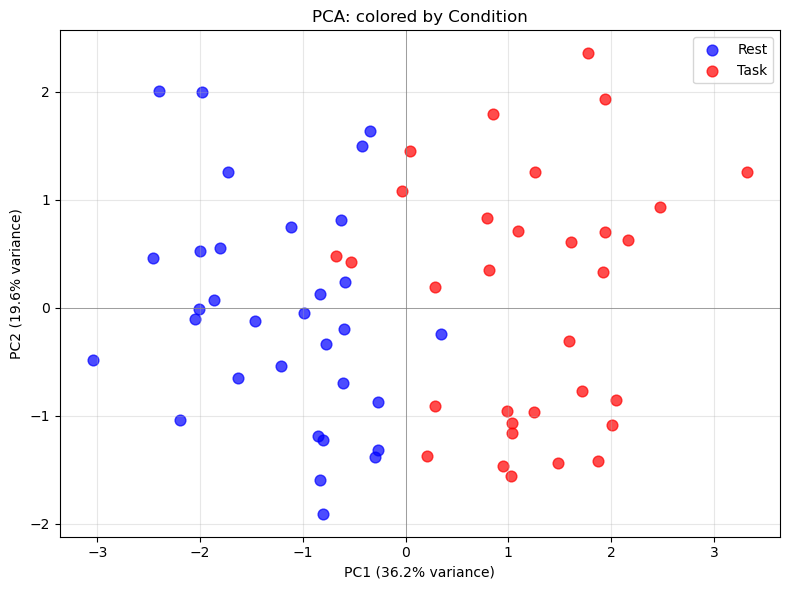

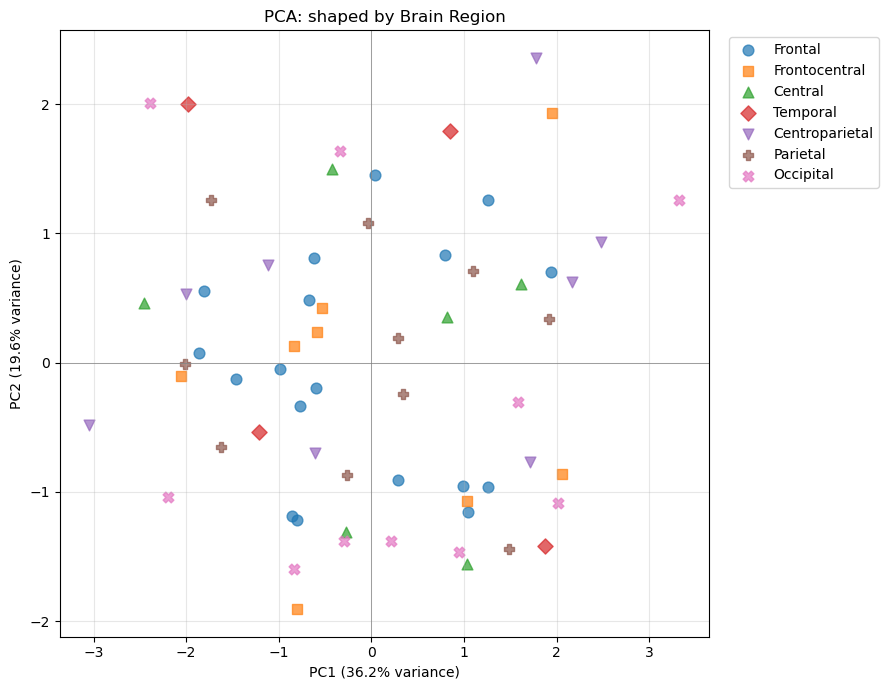

In [7]:
from sklearn.decomposition import PCA

# 6.5: PCA on standardized frequency-band features
columns_to_standardize = ['DeltaPower', 'ThetaPower', 'AlphaPower', 'BetaPower', 'GammaPower', 'Entropy']
for col in columns_to_standardize:
    df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()

z_columns = [c + '_z' for c in columns_to_standardize]
X = df[z_columns].values

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X)
df['PC1'] = pca_result[:, 0]
df['PC2'] = pca_result[:, 1]

print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"Variance explained by PC2: {pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum()*100:.1f}%")

# Plot 1: colored by condition
fig, ax = plt.subplots(figsize=(8, 6))
for condition, color in zip(['Rest', 'Task'], ['blue', 'red']):
    subset = df[df['Condition']==condition]
    ax.scatter(subset['PC1'], subset['PC2'], label=condition, color=color, s=60, alpha=0.7)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("PCA: colored by Condition")
ax.legend()
ax.grid(alpha=0.3)
ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)
plt.tight_layout()
plt.show()

# Plot 2: shaped by brain region
fig, ax = plt.subplots(figsize=(9, 7))
regions = df['Region'].unique()
markers = ['o', 's', '^', 'D', 'v', 'P', 'X']
for region, marker in zip(regions, markers):
    subset = df[df['Region']==region]
    ax.scatter(subset['PC1'], subset['PC2'], label=region, marker=marker, s=60, alpha=0.7)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("PCA: shaped by Brain Region")
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(alpha=0.3)
ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score

# 6.6: Classification - Logistic Regression

# One-hot encode Region
region_dummies = pd.get_dummies(df['Region'], prefix='Region', drop_first=True)

# Predictor matrix: standardized bands + region dummies
X = pd.concat([df[z_columns], region_dummies], axis=1)

# Target: Condition encoded as 0/1
y = (df['Condition'] == 'Task').astype(int)

print(f"Shape of X: {X.shape}")
print(f"Predictors: {list(X.columns)}")
print(f"\nTarget distribution:\n{y.value_counts()}")

# Train/test split, stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"\nTrain size: {len(X_train)}, Test size: {len(X_test)}")

# Fit logistic regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print(f"\nAccuracy on test set: {accuracy_score(y_test, y_pred):.3f}") 

Shape of X: (64, 12)
Predictors: ['DeltaPower_z', 'ThetaPower_z', 'AlphaPower_z', 'BetaPower_z', 'GammaPower_z', 'Entropy_z', 'Region_Centroparietal', 'Region_Frontal', 'Region_Frontocentral', 'Region_Occipital', 'Region_Parietal', 'Region_Temporal']

Target distribution:
Condition
0    32
1    32
Name: count, dtype: int64

Train size: 48, Test size: 16

Accuracy on test set: 0.938


Accuracy: 0.938
Sensitivity: 1.000
Specificity: 0.875

Confusion matrix:
[[7 1]
 [0 8]]

AUC: 0.984


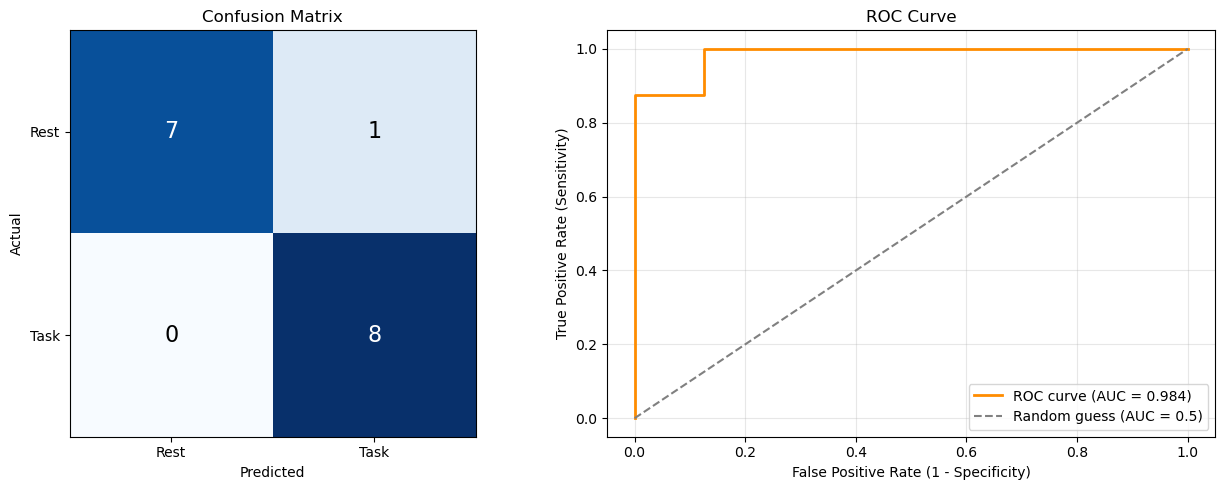

In [9]:
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score

# Confusion matrix and basic metrics
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
accuracy = accuracy_score(y_test, y_pred)
sensitivity = TP / (TP+FN)
specificity = TN / (TN+FP)

print(f"Accuracy: {accuracy:.3f}")
print(f"Sensitivity: {sensitivity:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"\nConfusion matrix:\n{cm}")

# ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)
print(f"\nAUC: {auc:.3f}")

# Plot: confusion matrix + ROC curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0,1])
axes[0].set_yticks([0,1])
axes[0].set_xticklabels(['Rest', 'Task'])
axes[0].set_yticklabels(['Rest', 'Task'])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i,j], ha='center', va='center', fontsize=16,
                      color='white' if cm[i,j] > cm.max()/2 else 'black')

axes[1].plot(fpr, tpr, color='darkorange', linewidth=2, label=f'ROC curve (AUC = {auc:.3f})')
axes[1].plot([0,1], [0,1], color='gray', linestyle='--', label='Random guess (AUC = 0.5)')
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Sensitivity)')
axes[1].set_title('ROC Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# 6.3: Feature Engineering

# Total Power: sum of all frequency bands
df['TotalPower'] = (df['DeltaPower'] + df['ThetaPower'] + df['AlphaPower'] +
                    df['BetaPower'] + df['GammaPower'])

# Relative Alpha: Alpha as a fraction of TotalPower
df['RelativeAlpha'] = df['AlphaPower'] / df['TotalPower']

# Relative Beta: Beta as a fraction of TotalPower
df['RelativeBeta'] = df['BetaPower'] / df['TotalPower']

# Cognitive Activation Index: (Beta + Gamma) / (Alpha + Theta)
df['CAI'] = (df['BetaPower'] + df['GammaPower']) / (df['AlphaPower'] + df['ThetaPower'])

print("New features added to df:")
print(df[['Channel', 'Condition', 'TotalPower', 'RelativeAlpha', 'RelativeBeta', 'CAI']].head(10))

print("\nMean by Condition:")
print(df.groupby('Condition')[['TotalPower', 'RelativeAlpha', 'RelativeBeta', 'CAI']].mean().round(4))

New features added to df:
  Channel Condition  TotalPower  RelativeAlpha  RelativeBeta       CAI
0     Fp1      Rest       36.68       0.220829      0.242366  0.936364
1     Fp2      Rest       32.39       0.219821      0.273850  0.860246
2      F3      Rest       40.24       0.195825      0.257455  0.928287
3      F4      Rest       40.07       0.190167      0.295233  1.037196
4      F7      Rest       44.41       0.230354      0.245891  0.793084
5      F8      Rest       42.81       0.221210      0.267461  0.820686
6     FC1      Rest       32.43       0.225717      0.275362  0.825668
7     FC2      Rest       36.18       0.216694      0.250691  0.903631
8      C3      Rest       36.44       0.209934      0.261251  0.867052
9      C4      Rest       40.93       0.246763      0.217933  0.594478

Mean by Condition:
           TotalPower  RelativeAlpha  RelativeBeta     CAI
Condition                                                 
Rest          38.6497         0.2299        0.2637  0.8